
# Exploratory Data Analysis (EDA)
## Freight Rate Prediction

### 1. Introduction

This notebook performs exploratory data analysis on the freight-rate dataset.

The objective is to understand the dataset's structure, identify data-quality issues, examine freight-rate distributions, and investigate patterns that may influence freight pricing.

### 2. Analysis Objectives

- Understand the dataset dimensions, columns, and data types.
- Identify missing values and duplicate records.
- Analyze the distribution of the target variable (`posted_rate`).
- Explore categorical features such as pickup, delivery, and equipment.
- Investigate numerical and temporal patterns.
- Identify potential outliers and useful predictive relationships.

### 3. Dataset

The primary dataset is `train-test.csv`, containing historical freight-load information and the target variable `posted_rate`.


In [2]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Load training dataset
df = pd.read_csv("../data/train-test.csv")

# Display basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()


Dataset Shape: (48000, 14)

First 5 Rows:


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09,-76.79,38.17,-72.75,274.30,Dry Van,"30,658.00",2025-01-01,0.96,2.40,645.41
1,TR-000002,Richmond,Philadelphia,38.09,-76.79,39.22,-72.97,280.50,Reefer,"17,555.00",2025-01-01,0.98,2.43,679.97
2,TR-000003,Philadelphia,Green Bay,39.22,-72.97,44.30,-87.53,967.80,Dry Van,"31,721.00",2025-01-01,1.01,1.84,"1,802.54"
3,TR-000004,Hartford,Atlanta,39.55,-72.18,34.85,-86.29,965.40,Dry Van,"32,333.00",2025-01-01,0.95,1.88,"1,827.28"
4,TR-000005,Dallas,Nashville,31.83,-94.38,35.29,-88.09,541.90,Reefer,"35,183.00",2025-01-01,0.98,2.56,"1,380.28"



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [3]:

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

# Missing value analysis
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nMissing Value Analysis:")
display(missing_values[missing_values["Missing Count"] > 0])

# Duplicate analysis
print("\nDuplicate Records:", df.duplicated().sum())

# Unique values in categorical columns
print("\nCategorical Feature Cardinality:")
for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values")


Numerical Columns:
['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']

Categorical Columns:
['load_id', 'pickup', 'delivery', 'equipment']

Missing Value Analysis:


,Missing Count,Missing Percentage
weight,300,0.62
market_index,374,0.78



Duplicate Records: 0

Categorical Feature Cardinality:
load_id: 48000 unique values
pickup: 64 unique values
delivery: 64 unique values
equipment: 3 unique values


Posted Rate Summary Statistics:


,posted_rate
count,"48,000.00"
mean,"2,373.98"
std,"1,486.49"
min,57.22
25%,"1,251.55"
50%,"2,030.76"
75%,"3,330.75"
max,"25,533.00"


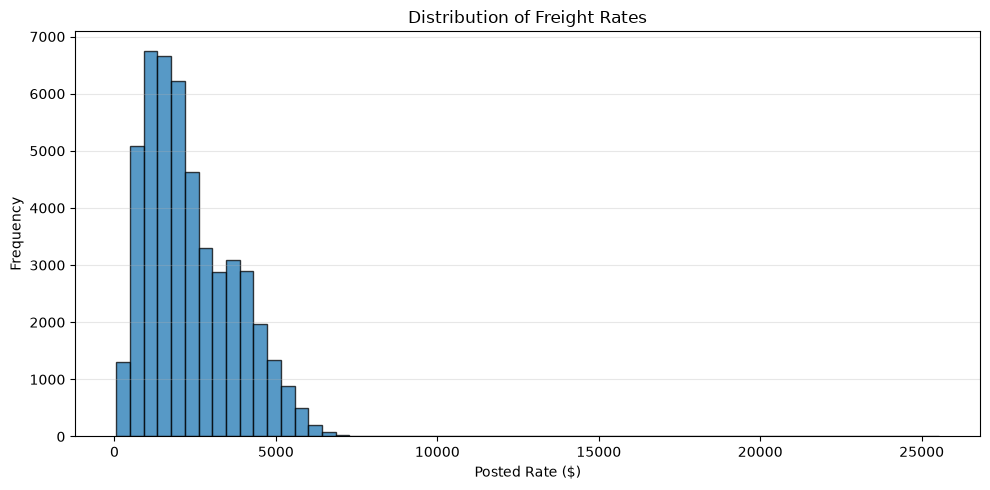

In [4]:

# Target variable statistical summary

print("Posted Rate Summary Statistics:")
display(df["posted_rate"].describe().to_frame())

# Distribution of posted rates
plt.figure(figsize=(10, 5))

plt.hist(
    df["posted_rate"],
    bins=60,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of Freight Rates")
plt.xlabel("Posted Rate ($)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Equipment-wise Rate Statistics:


,count,mean,median,std,min,max
equipment,,,,,,
Dry Van,27202,"2,271.55","1,953.04","1,423.03",57.22,"25,533.00"
Flatbed,8753,"2,445.09","2,076.81","1,505.05",157.76,"17,893.17"
Reefer,12045,"2,553.64","2,196.67","1,589.67",63.36,"24,140.21"


<Figure size 900x500 with 0 Axes>

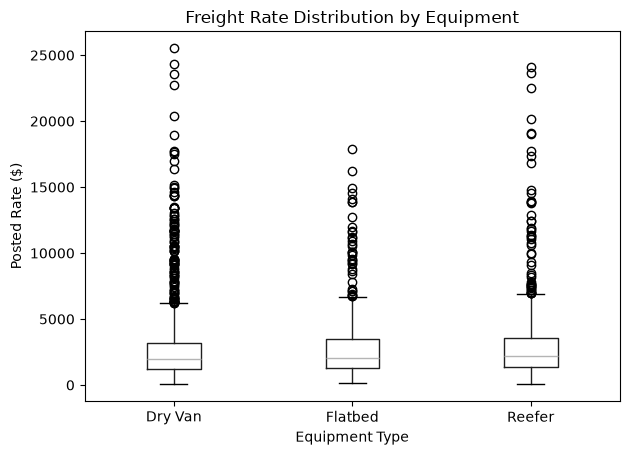

In [5]:

# Freight rate distribution by equipment type

print("Equipment-wise Rate Statistics:")

display(
    df.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# Boxplot by equipment
plt.figure(figsize=(9, 5))

df.boxplot(
    column="posted_rate",
    by="equipment",
    grid=False
)

plt.title("Freight Rate Distribution by Equipment")
plt.suptitle("")
plt.xlabel("Equipment Type")
plt.ylabel("Posted Rate ($)")
plt.tight_layout()
plt.show()


Monthly Freight Rate Statistics:


,mean,median,count
month,,,
1,"2,255.97","1,915.20",4918
2,"2,273.80","1,994.25",4337
3,"2,372.27","2,022.92",5036
4,"2,372.16","2,044.24",4819
5,"2,421.78","2,065.51",4913
6,"2,497.03","2,120.22",4783
7,"2,415.16","2,059.14",4912
8,"2,338.41","2,015.73",4759
9,"2,406.37","2,057.13",4670


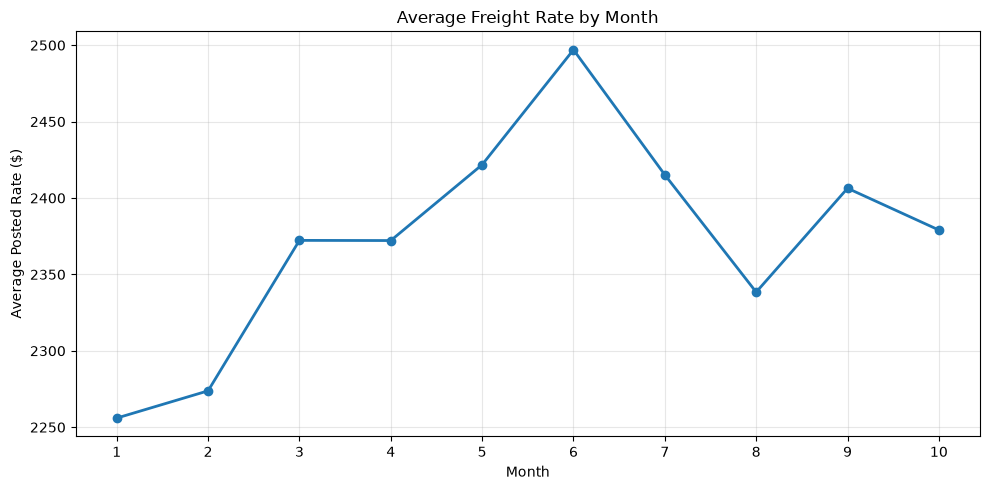

In [6]:

# Extract month from date
df["month"] = df["date"].dt.month

# Monthly freight-rate statistics
monthly_rates = (
    df.groupby("month")["posted_rate"]
    .agg(["mean", "median", "count"])
    .round(2)
)

print("Monthly Freight Rate Statistics:")
display(monthly_rates)

# Plot monthly average freight rates
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_rates.index,
    monthly_rates["mean"],
    marker="o",
    linewidth=2
)

plt.title("Average Freight Rate by Month")
plt.xlabel("Month")
plt.ylabel("Average Posted Rate ($)")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Monthly Freight Rate Analysis — Observations

- Average freight rates increased from January ($2,255.97) to June ($2,497.03).
- June recorded the highest average freight rate.
- Rates declined during July and August, followed by a recovery in September.
- October showed a slight decrease compared with September.
- Monthly mean rates consistently exceeded median rates, suggesting right-skewed distributions.
- Monthly record counts were relatively balanced.

**Conclusion:** Temporal features may provide useful predictive information because freight rates vary across the observed months.


Distance Statistics:


,distance
count,"48,000.00"
mean,"1,135.86"
std,728.56
min,70.00
25%,550.40
50%,953.30
75%,"1,645.53"
max,"3,439.80"



Correlation between Distance and Posted Rate:
0.9085


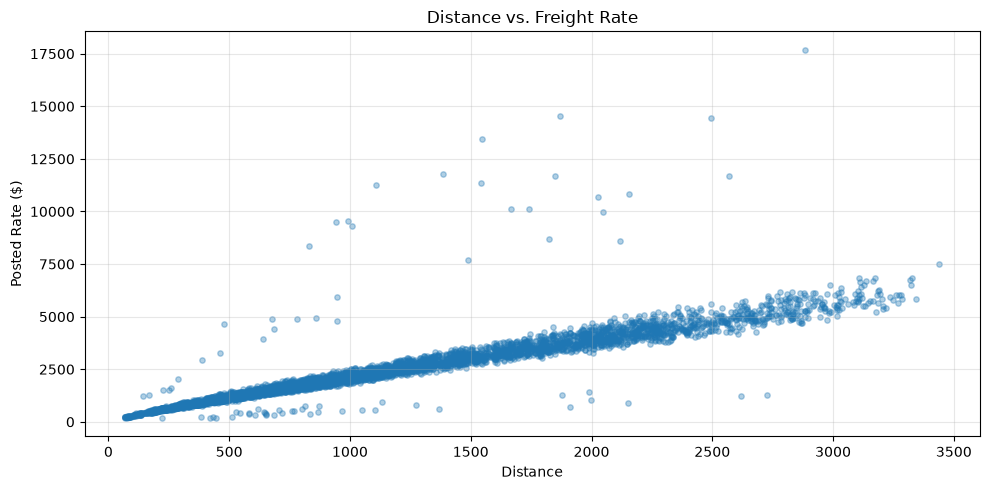

In [7]:

# Statistical relationship between distance and freight rate

print("Distance Statistics:")
display(df["distance"].describe().to_frame())

print("\nCorrelation between Distance and Posted Rate:")
print(df["distance"].corr(df["posted_rate"]).round(4))

# Scatter plot using a sample to improve readability
sample_df = df.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 5))

plt.scatter(
    sample_df["distance"],
    sample_df["posted_rate"],
    alpha=0.35,
    s=15
)

plt.title("Distance vs. Freight Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate ($)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Distance vs. Freight Rate — Observations

- The average shipment distance is 1,135.86, with a median of 953.30.
- Shipment distances range from 70.00 to 3,439.80.
- Distance has a strong positive Pearson correlation of 0.9085 with posted freight rates.
- Longer shipments generally correspond to higher freight rates.

**Conclusion:** Distance is an important candidate predictive feature and should be retained during model development.


Weight Statistics:


,weight
count,"47,700.00"
mean,"31,028.84"
std,"9,391.44"
min,"-47,500.00"
25%,"25,800.00"
50%,"31,436.50"
75%,"37,018.00"
max,"47,500.00"



Correlation between Weight and Posted Rate:
0.0348


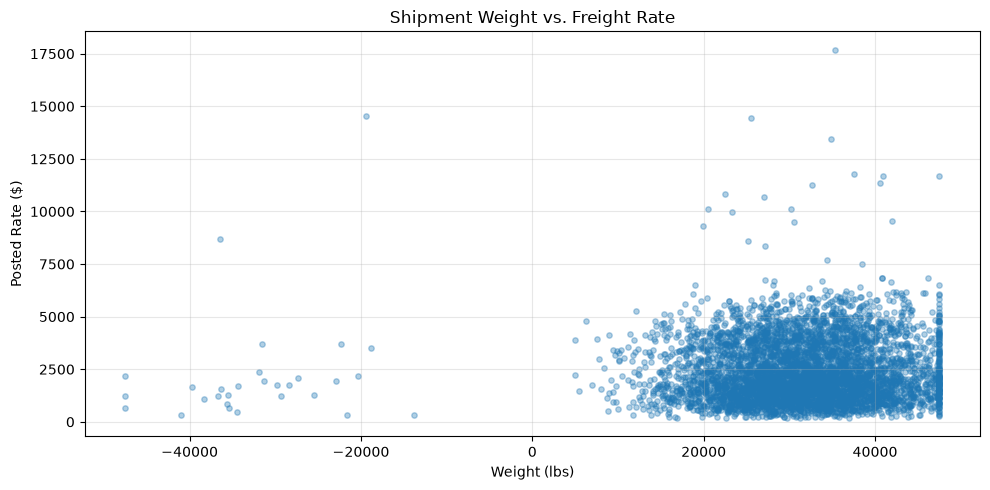

In [8]:

# Weight statistics
print("Weight Statistics:")
display(df["weight"].describe().to_frame())

# Correlation between weight and posted rate
weight_correlation = df["weight"].corr(df["posted_rate"])

print("\nCorrelation between Weight and Posted Rate:")
print(round(weight_correlation, 4))

# Scatter plot using a sample of 5,000 records
sample_df = df.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 5))

plt.scatter(
    sample_df["weight"],
    sample_df["posted_rate"],
    alpha=0.35,
    s=15
)

plt.title("Shipment Weight vs. Freight Rate")
plt.xlabel("Weight (lbs)")
plt.ylabel("Posted Rate ($)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:

# Investigate negative and missing shipment weights

negative_weights = df[df["weight"] < 0]
zero_weights = df[df["weight"] == 0]
missing_weights = df[df["weight"].isna()]

print("Negative weight records:", len(negative_weights))
print("Zero weight records:", len(zero_weights))
print("Missing weight records:", len(missing_weights))

print("\nPercentage of negative weights:")
print(round(len(negative_weights) / len(df) * 100, 3), "%")

print("\nSample negative-weight records:")
display(
    negative_weights[
        ["load_id", "pickup", "delivery", "distance", "weight", "posted_rate"]
    ].head(10)
)


Negative weight records: 292
Zero weight records: 0
Missing weight records: 300

Percentage of negative weights:
0.608 %

Sample negative-weight records:


,load_id,pickup,delivery,distance,weight,posted_rate
68,TR-000069,Amarillo,Dayton,"1,334.20","-36,559.00","2,831.27"
204,TR-000205,Fresno,Tucson,496.20,"-26,670.00","1,046.92"
206,TR-000207,Columbia,Raleigh,411.30,"-20,003.00",959.15
225,TR-000226,Greensboro,Lubbock,"1,317.40","-23,981.00","2,836.00"
376,TR-000377,Madison,Providence,"1,331.10","-41,397.00","2,522.54"
446,TR-000447,Albuquerque,Albany,"2,438.30","-37,215.00","4,841.57"
495,TR-000496,Montgomery,Dayton,715.90,"-31,214.00","1,473.78"
641,TR-000642,Tulsa,Indianapolis,582.40,"-41,023.00","1,264.33"
806,TR-000807,Cincinnati,Buffalo,676.10,"-28,320.00","1,307.76"
1093,TR-001094,Cincinnati,Albany,"1,058.50","-25,153.00","1,907.83"


In [10]:

# Correlation using all available weight values
original_correlation = df["weight"].corr(df["posted_rate"])

# Treat negative weights as invalid
valid_weight_df = df[df["weight"] > 0]

valid_correlation = valid_weight_df["weight"].corr(
    valid_weight_df["posted_rate"]
)

print("Correlation including negative weights:", round(original_correlation, 4))
print("Correlation using only positive weights:", round(valid_correlation, 4))
print("Records with valid positive weights:", len(valid_weight_df))


Correlation including negative weights: 0.0348
Correlation using only positive weights: 0.0417
Records with valid positive weights: 47408



### Weight vs. Freight Rate — Observations

- The average shipment weight is 31,028.84 lbs, with a median of 31,436.50 lbs.
- The dataset contains 292 negative weight values (0.608%), which are physically invalid.
- Another 300 records (0.625%) have missing weight values.
- The Pearson correlation between weight and posted rate is 0.0348 when all available values are included.
- After excluding negative weights, the correlation increases slightly to 0.0417, which still indicates a very weak linear relationship.

**Conclusion:** Negative weights will be treated as missing values, and missing weights will be imputed during preprocessing. Weight will be retained as a candidate feature because a weak linear correlation does not rule out nonlinear predictive relationships.


In [11]:

# Analyze average freight rates by pickup location
pickup_rates = (
    df.groupby("pickup")["posted_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("Top 10 Pickup Locations by Average Freight Rate:")
display(pickup_rates.head(10).round(2))

# Analyze average freight rates by delivery location
delivery_rates = (
    df.groupby("delivery")["posted_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("\nTop 10 Delivery Locations by Average Freight Rate:")
display(delivery_rates.head(10).round(2))


Top 10 Pickup Locations by Average Freight Rate:


,count,mean,median
pickup,,,
San Francisco,453,"4,071.21","4,301.81"
Fresno,827,"3,878.91","4,160.28"
Reno,642,"3,765.39","3,836.92"
Phoenix,1121,"3,764.77","3,935.62"
Los Angeles,945,"3,729.64","3,996.61"
Bakersfield,1193,"3,519.37","3,804.88"
Tucson,944,"3,311.00","3,536.00"
Las Vegas,277,"3,292.82","3,633.06"
Salt Lake City,394,"3,144.76","3,316.26"



Top 10 Delivery Locations by Average Freight Rate:


,count,mean,median
delivery,,,
San Francisco,467,"4,064.47","4,356.60"
Fresno,763,"3,865.38","4,140.17"
Phoenix,1090,"3,751.47","3,921.98"
Los Angeles,955,"3,742.25","4,046.09"
Reno,653,"3,679.87","3,783.88"
Bakersfield,1156,"3,532.20","3,742.54"
Las Vegas,292,"3,428.38","3,707.76"
Tucson,997,"3,363.19","3,591.79"
Salt Lake City,406,"3,164.35","3,316.06"


In [12]:

# Create route-level groups
df["route"] = df["pickup"] + " -> " + df["delivery"]

route_rates = (
    df.groupby("route")["posted_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print("10 Most Frequent Routes:")
display(route_rates.head(10).round(2))

print("\n10 Highest Average-Rate Routes (minimum 30 records):")

high_rate_routes = (
    route_rates[route_rates["count"] >= 30]
    .sort_values("mean", ascending=False)
)

display(high_rate_routes.head(10).round(2))


10 Most Frequent Routes:


,count,mean,median
route,,,
Columbia -> Oklahoma City,39,"2,330.73","2,327.43"
Phoenix -> Shreveport,39,"3,507.62","3,554.43"
Lexington -> Atlanta,39,560.11,553.63
Fort Wayne -> Philadelphia,38,"1,681.03","1,708.84"
Shreveport -> Hartford,37,"2,867.77","2,812.52"
Fort Wayne -> Hartford,37,"1,938.66","1,725.99"
Richmond -> Oklahoma City,37,"3,093.44","3,126.49"
Richmond -> Phoenix,37,"5,190.19","5,010.88"
Lexington -> Kansas City,37,"1,042.47","1,029.80"



10 Highest Average-Rate Routes (minimum 30 records):


,count,mean,median
route,,,
Bakersfield -> Hartford,35,"5,998.48","5,402.59"
Richmond -> Phoenix,37,"5,190.19","5,010.88"
Bakersfield -> Richmond,30,"5,002.02","4,962.47"
Richmond -> Bakersfield,32,"4,985.75","5,016.04"
Atlanta -> Phoenix,30,"4,430.90","4,116.02"
Phoenix -> Lexington,31,"4,395.76","4,117.77"
Phoenix -> Nashville,31,"4,358.13","3,930.73"
Hartford -> Amarillo,32,"4,238.38","4,235.19"
Mobile -> Phoenix,36,"4,180.47","3,842.00"



### Route-Level Freight Rate Analysis — Observations

- Columbia -> Oklahoma City and Phoenix -> Shreveport are the most frequent routes, with 39 records each.
- Lexington -> Atlanta also has 39 records, but its average freight rate is only $560.11.
- Bakersfield -> Hartford has the highest average freight rate ($5,998.48) among routes with at least 30 observations.
- Richmond -> Phoenix has the second-highest average rate ($5,190.19).
- Route frequency does not necessarily indicate a higher freight rate.
- Considerable variation exists between average freight rates across different routes.

**Conclusion:** Pickup and delivery locations are potentially important categorical features. Their combination may capture route-specific pricing patterns.


Market Feature Statistics:


,market_index,quote_signal
count,"47,626.00","48,000.00"
mean,1.08,2.06
std,0.17,0.29
min,0.68,0.69
25%,0.95,1.89
50%,1.06,2.06
75%,1.22,2.22
max,1.47,3.61



Correlation with Posted Rate:


,Correlation
market_index,0.03
quote_signal,-0.04


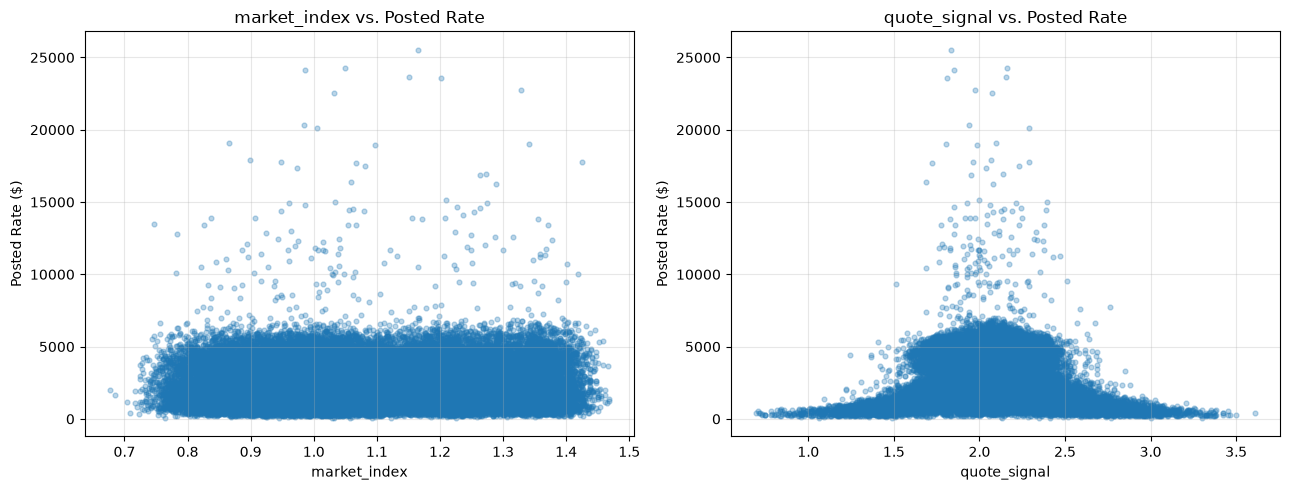

In [13]:

# Summary statistics for market-related features
market_features = ["market_index", "quote_signal"]

print("Market Feature Statistics:")
display(df[market_features].describe().round(4))

# Correlation with posted freight rate
market_correlations = (
    df[market_features + ["posted_rate"]]
    .corr()["posted_rate"]
    .drop("posted_rate")
)

print("\nCorrelation with Posted Rate:")
display(market_correlations.to_frame("Correlation").round(4))

# Scatter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, market_features):
    ax.scatter(
        df[feature],
        df["posted_rate"],
        alpha=0.3,
        s=12
    )
    ax.set_title(f"{feature} vs. Posted Rate")
    ax.set_xlabel(feature)
    ax.set_ylabel("Posted Rate ($)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Market Conditions and Quote Signal — Observations

- The market index has a mean of 1.08 and a standard deviation of 0.17.
- The quote signal has a mean of 2.06 and a standard deviation of 0.29.
- The Pearson correlation between market index and posted rate is approximately 0.03.
- The Pearson correlation between quote signal and posted rate is approximately -0.04.
- Market index contains 374 missing values (0.78% of the dataset).
- Quote signal has no missing values.

**Conclusion:** Both features exhibit very weak linear relationships with posted rates. Although they may contain additional nonlinear information, they are excluded from the current prediction pipeline because the December input dataset does not provide these features.


Daily Freight Rate Summary:


,mean,median,count
count,304.00,304.00,304.00
mean,"2,374.36","2,031.94",157.89
std,132.65,142.32,12.44
min,"2,041.05","1,626.40",115.00
25%,"2,284.55","1,933.81",150.00
50%,"2,380.53","2,033.74",157.00
75%,"2,457.94","2,124.06",166.00
max,"2,756.38","2,488.57",198.00


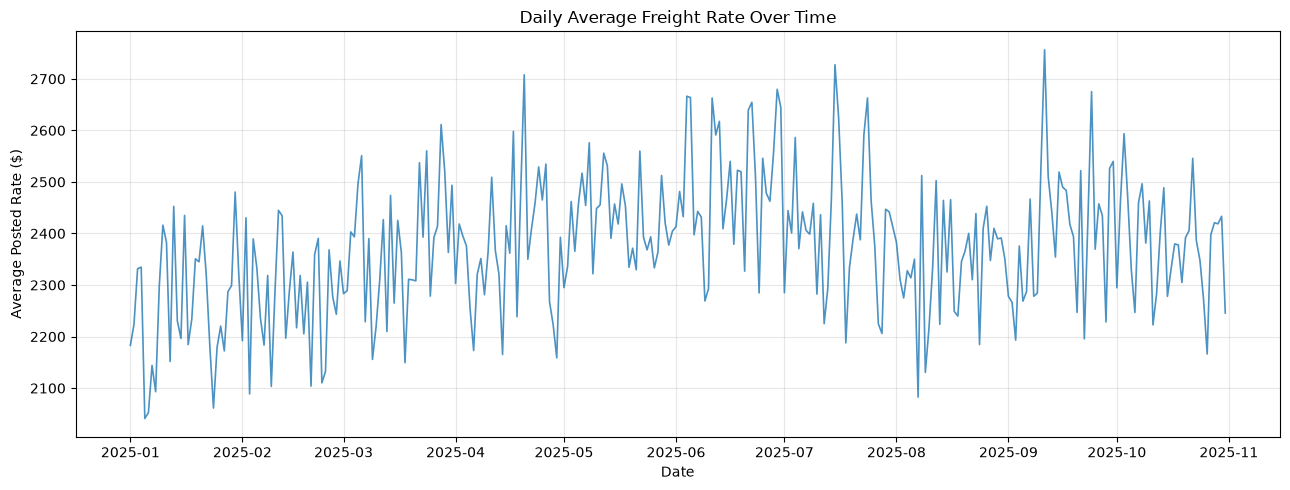

In [14]:

# Group freight rates by date
daily_rates = (
    df.groupby("date")["posted_rate"]
    .agg(["mean", "median", "count"])
)

print("Daily Freight Rate Summary:")
display(daily_rates.describe().round(2))

# Plot daily average freight rates
plt.figure(figsize=(13, 5))

plt.plot(
    daily_rates.index,
    daily_rates["mean"],
    linewidth=1.2,
    alpha=0.8
)

plt.title("Daily Average Freight Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Average Posted Rate ($)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Daily Freight Rate Analysis — Observations

- The dataset contains 304 distinct shipment dates.
- The average daily freight rate is $2,374.36.
- Daily average rates range from $2,041.05 to $2,756.38.
- The standard deviation of daily average rates is $132.65.
- An average of approximately 158 shipments are recorded per day.
- Daily shipment counts range from 115 to 198.

**Conclusion:** Freight rates exhibit daily variation, although daily average rates are considerably less dispersed than individual shipment rates. Date-based features may help capture temporal pricing patterns.


In [15]:

# Calculate the interquartile range (IQR)
Q1 = df["posted_rate"].quantile(0.25)
Q3 = df["posted_rate"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df["posted_rate"] < lower_bound) |
    (df["posted_rate"] > upper_bound)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("\nPotential Outliers:", len(outliers))
print(
    "Outlier Percentage:",
    round(len(outliers) / len(df) * 100, 2),
    "%"
)

print("\nOutlier Rate Summary:")
display(outliers["posted_rate"].describe().to_frame().round(2))


Q1: 1251.55
Q3: 3330.75
IQR: 2079.2
Lower Bound: -1867.24
Upper Bound: 6449.54

Potential Outliers: 260
Outlier Percentage: 0.54 %

Outlier Rate Summary:


,posted_rate
count,260.00
mean,"9,940.30"
std,"4,005.16"
min,"6,450.50"
25%,"6,689.96"
50%,"8,612.13"
75%,"11,713.74"
max,"25,533.00"


In [16]:

# Inspect the 10 highest freight-rate records
highest_rates = (
    df.nlargest(10, "posted_rate")
    [
        [
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "posted_rate"
        ]
    ]
)

display(highest_rates.round(2))


,pickup,delivery,distance,equipment,weight,posted_rate
12184,Bakersfield,Hartford,"2,829.80",Dry Van,"33,153.00","25,533.00"
37764,Phoenix,Syracuse,"2,810.90",Dry Van,"33,674.00","24,294.98"
1466,Los Angeles,Syracuse,"2,786.00",Reefer,"30,322.00","24,140.21"
17371,Reno,Philadelphia,"2,777.60",Reefer,"33,158.00","23,662.71"
26235,Charleston,Phoenix,"2,552.50",Dry Van,"25,665.00","23,580.42"
28219,Tucson,Raleigh,"2,423.30",Dry Van,"30,972.00","22,755.66"
3353,Phoenix,Charleston,"2,527.90",Reefer,"36,840.00","22,534.65"
40171,Montgomery,Fresno,"2,283.40",Dry Van,"32,447.00","20,361.89"
40096,Baltimore,Oklahoma City,"1,760.30",Reefer,"29,521.00","20,132.37"
47298,Boston,Bakersfield,"2,979.10",Reefer,"30,585.00","19,110.30"



### Freight Rate Outlier Analysis — Observations

- The IQR method identified 260 potential outliers, representing 0.54% of the dataset.
- All identified outliers are above the upper IQR boundary of $6,449.54.
- The highest recorded freight rate is $25,533.00.
- Inspection of the 10 highest-rate records shows that these shipments generally involve long distances.
- Both Dry Van and Reefer equipment types appear among the highest-priced shipments.
- The inspected records do not show an obvious data-entry error.

**Conclusion:** Potential outliers will be retained because they may represent legitimate high-value freight transactions. Automatic removal could eliminate useful pricing information and negatively affect model generalization.



## Final Exploratory Data Analysis Summary

### 1. Dataset Overview
- The training dataset contains 48,000 records and 14 columns.
- The target variable is `posted_rate`.
- The dataset contains 64 unique pickup locations, 64 unique delivery locations, and 3 equipment categories.
- No duplicate records were identified.

### 2. Data Quality
- The `weight` feature contains 300 missing values and 292 negative values.
- The `market_index` feature contains 374 missing values.
- Negative weights are physically invalid and should be treated as missing values.
- No duplicate records were found.

### 3. Target Variable
- The average posted rate is $2,373.98.
- The median posted rate is $2,030.76.
- The target distribution is right-skewed.
- The IQR method identified 260 potential high-rate outliers (0.54%).

### 4. Feature Relationships
- Distance has a strong positive correlation with posted rate (0.9085).
- Weight has a very weak positive correlation (0.0417 after excluding negative values).
- Market index has a weak positive correlation (0.03).
- Quote signal has a weak negative correlation (-0.04).
- Pickup and delivery locations show considerable variation in average freight rates.
- Equipment categories also exhibit differences in freight-rate distributions.

### 5. Temporal Patterns
- Monthly average freight rates vary throughout the observed period.
- June has the highest monthly average rate.
- Daily average rates also exhibit variation over time.
- Date-derived features may help capture temporal pricing patterns.

### 6. Modeling Implications
- Retain distance, pickup, delivery, equipment, weight, and date-derived features.
- Replace negative weights with missing values before imputation.
- Impute missing numerical values using the median.
- Encode categorical features using one-hot encoding.
- Retain potential target outliers unless further investigation establishes that they are erroneous.
- Use a chronological validation strategy to evaluate performance on later periods.
- Exclude market index and quote signal from the current prediction pipeline because these features are unavailable in the December input dataset.

### Overall Conclusion

The exploratory analysis indicates that distance, route information, equipment type, and temporal features are useful candidates for freight-rate prediction. Data-quality issues in weight and market index require appropriate preprocessing. These findings guide the feature engineering, preprocessing, and model development stages.
